### Visualizing Housing Data

In [1]:
import pandas as pd

In [15]:
path = "data/mexico-real-estate-combined-clean.csv"
df =pd.read_csv(path)

In [17]:
print(f"Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns")

print("\nData Types and Non-Null Counts:")
df.info()

print("\nSample Records:")
display(df.head())

Dataset Shape: 1854 rows × 6 columns

Data Types and Non-Null Counts:
<class 'pandas.DataFrame'>
RangeIndex: 1854 entries, 0 to 1853
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1854 non-null   str    
 1   state          1854 non-null   str    
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1854 non-null   float64
 5   price_usd      1854 non-null   float64
dtypes: float64(4), str(2)
memory usage: 87.0 KB

Sample Records:


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


##### 1. Univariate Analysis: Understanding One Variable at a Time

> What is a histogram?
>
> A histogram divides a numerical variable into bins and shows the frequency of observations in each bin.
>
> It helps identify:
> - Center — where values cluster
> - Spread — how widely values vary
> - Skewness — direction of the tail
> - Modality — number of peaks
> - Outliers — unusual or isolated values
>
> Bins control the level of detail. Too few can hide patterns, while too many can show noise. Start with a reasonable number and adjust based on the distribution.

**Histogram of price_usd**

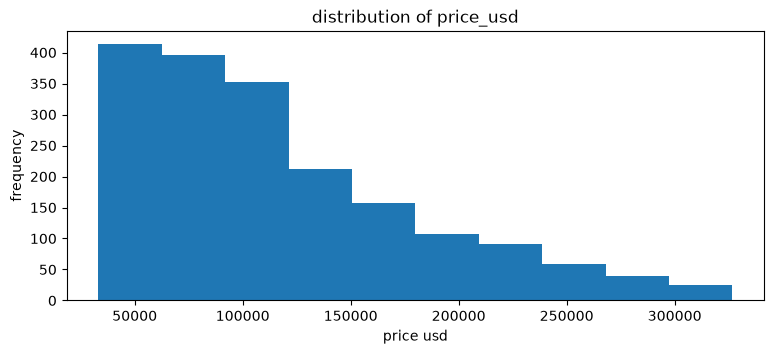

In [18]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9,3.5))
ax.hist(df["price_usd"])
ax.set_xlabel("price usd")
ax.set_ylabel("frequency")
ax.set_title("distribution of price_usd")
plt.show()

> Shape: The distribution is strongly right-skewed. Most properties are concentrated around 30,000–130,000, with a long tail extending toward 300,000+.
>
> What this means:
> - A small number of expensive properties pull the mean above the median.
> - The median is therefore a better measure of a typical property price.
> - Extreme values can strongly influence models that minimize squared errors.
> - A log transformation such as `np.log(df["price_usd"])` can help reduce right skew.
>
> Practical implication:
> When comparing typical property prices across states, use the median rather than the mean because it is less affected by extreme prices.

> When does right skew matter for analysis?
>
> 1. Measure of center
> - In a right-skewed distribution, the mean is pulled above the median by extreme values.
> - The median is usually a better measure of a typical value.
> 
> 2. Outlier sensitivity
> - Models that minimize squared errors, such as linear regression, are sensitive to extreme values.
> - Large outliers can have a strong influence on the fitted model.
> 
> 3. Log transformation
> - A common approach for right-skewed data is to use a log transformation:
>   `np.log(df["price_usd"])`
> - This can reduce skewness and make the distribution more symmetric.
> 
> 4. Visualization
> - A long right tail can compress most observations into a small part of the histogram.
> - Outlier handling or transformation can make patterns easier to visualize.

**Histogram of  area_m2**

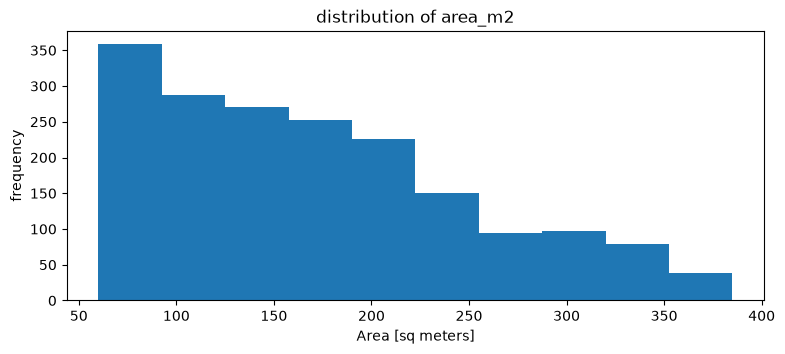

In [20]:
fig, ax = plt.subplots(figsize=(9,3.5))
ax.hist(df["area_m2"])
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("frequency")
ax.set_title("distribution of area_m2")
plt.show()